# 02 · Experiment 1 — single-modality baselines vs. multimodal fusion

**Research question (Exp. 1):** does combining voice and face-image evidence beat each modality alone?

Systems compared (all trained on the frozen embeddings from `01_extract_features`, logistic regression head, `C` tuned on the validation set):

| System | Input |
|---|---|
| Audio only | Wav2Vec2 (best layer chosen on validation) |
| Image only | CLIP ViT-B/32 on face crops |
| Text only (CLIP) | CLIP-text embedding of the Whisper transcript |
| Text only (TF-IDF) | word 1–2-gram TF-IDF of the Whisper transcript |
| **Audio + Image** | early fusion (concatenation) — the project's core voice + image setting |
| **Audio + Image + Text** | early fusion of all three streams |

Metrics: accuracy, precision, recall, F1 (FAKE = positive class), macro-F1, ROC-AUC, PR-AUC, confusion matrices,
per-category accuracy (RVRA / RVFA / FVRA / FVFA) and a repeated speaker-grouped re-split for mean ± std.

Works on Kaggle (reads `features.npz` + `meta.csv` from your saved output/dataset) and locally.

In [4]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, classification_report)

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

SEED = 42
N_RESPLITS = 5
CS = [1e-3, 1e-2, 1e-1, 1, 10]
OUT = os.environ.get("EXP_OUT", "/kaggle/working/exp1")
os.makedirs(OUT, exist_ok=True)

def find(name):
    cands = []
    if os.environ.get("FEAT_DIR"):
        cands.append(os.path.join(os.environ["FEAT_DIR"], name))
    cands.append(os.path.join("/kaggle/working/features", name))
    cands += glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for c in cands:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"{name} not found. Run 01_extract_features first or add its output as an input dataset.")

FEAT_NPZ, META_CSV = find("features.npz"), find("meta.csv")
print("features:", FEAT_NPZ, "\nmeta:    ", META_CSV)

features: /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/features.npz 
meta:     /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/meta.csv


## 1 · Load features

In [5]:
Z = np.load(FEAT_NPZ)
meta = pd.read_csv(META_CSV).sort_values("clip_id").reset_index(drop=True)
assert (Z["clip_id"] == meta.clip_id.values).all(), "features.npz and meta.csv are out of sync"

keep = ((meta.ok_img == 1) & (meta.ok_aud == 1)).values
print(f"dropping {int((~keep).sum())} clips with failed image/audio decode")
meta = meta[keep].reset_index(drop=True)
A_LAYERS, IMG, TXT = Z["audio_layers"][keep], Z["image"][keep], Z["text"][keep]
texts = meta.transcript.fillna("").astype(str).values
y = meta.label.values                       # 1 = FAKE
groups = meta.speaker.values
cats = meta.category.values

print("clips:", len(meta), "| REAL:", int((y == 0).sum()), "| FAKE:", int((y == 1).sum()))
print(pd.crosstab(meta.split, meta.category).to_string())

tr0 = np.where(meta.split == "train")[0]
va0 = np.where(meta.split == "val")[0]
te0 = np.where(meta.split == "test")[0]
print(f"\nmain split  train={len(tr0)}  val={len(va0)}  test={len(te0)}  (split by speaker)")
print("majority-class accuracy on test:", round(max((y[te0] == 0).mean(), (y[te0] == 1).mean()), 3), "(anything near this is no better than guessing)")

dropping 0 clips with failed image/audio decode
clips: 998 | REAL: 500 | FAKE: 498
category  FVFA  FVRA  RVFA  RVRA
split                           
test        30    26    23    75
train      108   112   123   350
val         28    28    20    75

main split  train=693  val=151  test=154  (split by speaker)
majority-class accuracy on test: 0.513 (anything near this is no better than guessing)


## 2 · Pipeline: features → scaling → logistic regression (C tuned on validation only)

In [6]:
def metrics(yt, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(acc=accuracy_score(yt, yh), precision=precision_score(yt, yh, zero_division=0),
                recall=recall_score(yt, yh, zero_division=0), f1=f1_score(yt, yh, zero_division=0),
                macro_f1=f1_score(yt, yh, average="macro", zero_division=0),
                roc_auc=roc_auc_score(yt, p), pr_auc=average_precision_score(yt, p))

def scale(tr, *others):
    sc = StandardScaler().fit(tr)
    return (sc.transform(tr),) + tuple(sc.transform(o) for o in others)

def fit_lr(Xtr, ytr, Xva, yva):
    best = None
    for C in CS:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(Xtr, ytr)
        auc = roc_auc_score(yva, clf.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]:
            best = (auc, C, clf)
    return best[2], best[1], best[0]

def build(tr, va, te):
    """Return {system: (Xtr, Xva, Xte)} and the chosen audio layer. All fitting uses train only; layer choice uses val only."""
    def audio_mat(layer):
        return A_LAYERS.mean(1) if layer == "mean" else A_LAYERS[:, layer]

    best_layer, best_auc = None, -1
    for layer in ["mean"] + list(range(A_LAYERS.shape[1])):
        M = audio_mat(layer)
        a_tr, a_va = scale(M[tr], M[va])
        clf = LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000).fit(a_tr, y[tr])
        auc = roc_auc_score(y[va], clf.predict_proba(a_va)[:, 1])
        if auc > best_auc:
            best_layer, best_auc = layer, auc

    M = audio_mat(best_layer)
    A = scale(M[tr], M[va], M[te])
    I = scale(IMG[tr], IMG[va], IMG[te])
    T = scale(TXT[tr], TXT[va], TXT[te])
    tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(texts[tr])
    TF = (tf.transform(texts[tr]), tf.transform(texts[va]), tf.transform(texts[te]))
    fuse = lambda parts: tuple(np.hstack([p[i] for p in parts]) for i in range(3))

    feats = {
        "Audio only (Wav2Vec2)": A,
        "Image only (CLIP, face crop)": I,
        "Text only (CLIP of ASR)": T,
        "Text only (TF-IDF of ASR)": TF,
        "Audio + Image (early fusion)": fuse([A, I]),
        "Audio + Image + Text (early fusion)": fuse([A, I, T]),
    }
    return feats, best_layer

def run_split(tr, va, te):
    feats, layer = build(tr, va, te)
    rows, probs = [], {}
    for name, (Xtr, Xva, Xte) in feats.items():
        clf, C, _ = fit_lr(Xtr, y[tr], Xva, y[va])
        p = clf.predict_proba(Xte)[:, 1]
        rows.append(dict(system=name, C=C, **metrics(y[te], p)))
        probs[name] = p
    return pd.DataFrame(rows).set_index("system"), probs, layer

## 3 · Main result (fixed speaker-disjoint split)

In [7]:
res, probs, layer = run_split(tr0, va0, te0)
print("audio layer selected on validation:", layer, "(0 = CNN features, 12 = last transformer layer, 'mean' = average over layers)\n")
display(res.round(3))
res.round(4).to_csv(f"{OUT}/exp1_main_results.csv")

audio layer selected on validation: mean (0 = CNN features, 12 = last transformer layer, 'mean' = average over layers)



,C,acc,precision,recall,f1,macro_f1,roc_auc,pr_auc
system,,,,,,,,
Audio only (Wav2Vec2),0.001,0.818,0.964,0.671,0.791,0.815,0.825,0.884
"Image only (CLIP, face crop)",0.010,0.740,0.747,0.747,0.747,0.740,0.797,0.814
Text only (CLIP of ASR),0.001,0.604,0.618,0.595,0.606,0.604,0.621,0.653
Text only (TF-IDF of ASR),10.000,0.513,0.531,0.430,0.476,0.510,0.484,0.508
Audio + Image (early fusion),0.010,0.825,0.861,0.785,0.821,0.825,0.925,0.939
Audio + Image + Text (early fusion),0.100,0.838,0.897,0.772,0.830,0.837,0.915,0.933


## 4 · Confusion matrices and ROC curves

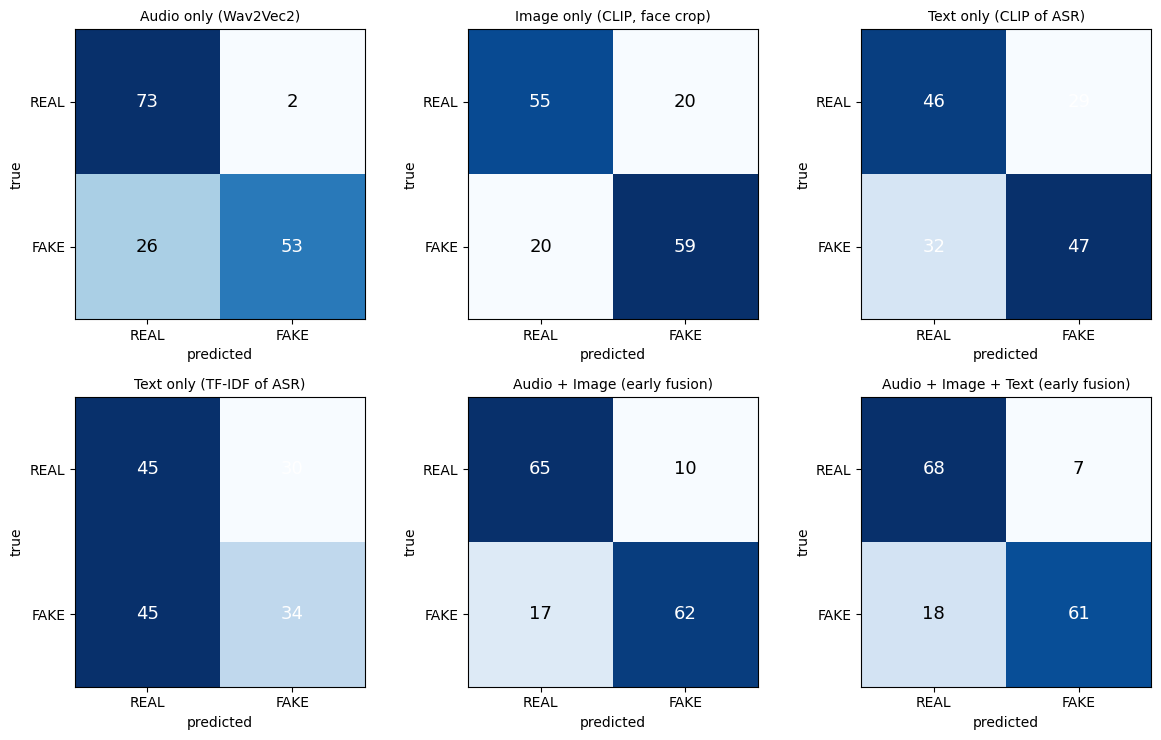

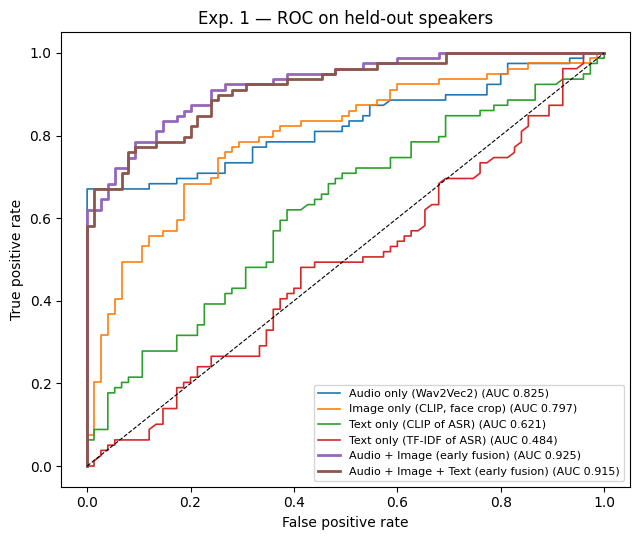

In [8]:
names = list(probs)
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, n in zip(axes.ravel(), names):
    cm = confusion_matrix(y[te0], (probs[n] >= 0.5).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["REAL", "FAKE"]); ax.set_yticklabels(["REAL", "FAKE"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(n, fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/exp1_confusion_matrices.png", dpi=160); plt.show()

plt.figure(figsize=(6.5, 5.5))
for n in names:
    fpr, tpr, _ = roc_curve(y[te0], probs[n])
    plt.plot(fpr, tpr, label=f"{n} (AUC {res.loc[n, 'roc_auc']:.3f})", lw=2 if "+" in n else 1.2)
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("Exp. 1 — ROC on held-out speakers")
plt.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.savefig(f"{OUT}/exp1_roc.png", dpi=160); plt.show()

## 5 · Where does each modality help? Accuracy per FakeAVCeleb category

RVRA = real (so this column is the true-negative rate); RVFA = only the voice is fake; FVRA = only the face is fake; FVFA = both.
A voice-only detector *should* struggle on FVRA and an image-only detector on RVFA — this table is the cleanest evidence for the "multimodal helps" claim.

In [9]:
rows = {}
for n in names:
    pred = (probs[n] >= 0.5).astype(int)
    rows[n] = {c: (pred[cats[te0] == c] == y[te0][cats[te0] == c]).mean() if (cats[te0] == c).any() else np.nan
               for c in ["RVRA", "RVFA", "FVRA", "FVFA"]}
bycat = pd.DataFrame(rows).T
display(bycat.round(3))
print("test clips per category:", pd.Series(cats[te0]).value_counts().to_dict())
bycat.round(4).to_csv(f"{OUT}/exp1_per_category_accuracy.csv")

,RVRA,RVFA,FVRA,FVFA
Audio only (Wav2Vec2),0.973,1.000,0.000,1.000
"Image only (CLIP, face crop)",0.733,0.391,0.923,0.867
Text only (CLIP of ASR),0.613,0.739,0.423,0.633
Text only (TF-IDF of ASR),0.600,0.522,0.269,0.500
Audio + Image (early fusion),0.867,1.000,0.385,0.967
Audio + Image + Text (early fusion),0.907,0.957,0.385,0.967


test clips per category: {'RVRA': 75, 'FVFA': 30, 'FVRA': 26, 'RVFA': 23}


## 6 · Class-wise report for the core voice + image system

In [10]:
core = "Audio + Image (early fusion)"
rep = classification_report(y[te0], (probs[core] >= 0.5).astype(int), target_names=["REAL", "FAKE"], digits=3)
print(core, "\n", rep)
with open(f"{OUT}/exp1_classwise_{core.split(' (')[0].replace(' + ', '_').replace(' ', '')}.txt", "w") as f:
    f.write(rep)

Audio + Image (early fusion) 
               precision    recall  f1-score   support

        REAL      0.793     0.867     0.828        75
        FAKE      0.861     0.785     0.821        79

    accuracy                          0.825       154
   macro avg      0.827     0.826     0.825       154
weighted avg      0.828     0.825     0.825       154



## 7 · Robustness: repeat with 5 different speaker-disjoint splits (mean ± std)

One split can be lucky. Because the heads train in seconds, re-run everything (including the audio-layer choice) on several random speaker-grouped splits.

In [11]:
def grouped_split(seed, val=0.15, test=0.15):
    idx = np.arange(len(y))
    trv, te = next(GroupShuffleSplit(1, test_size=test, random_state=seed).split(idx, groups=groups))
    a, b = next(GroupShuffleSplit(1, test_size=val / (1 - test), random_state=seed).split(trv, groups=groups[trv]))
    return trv[a], trv[b], te

runs = []
for s in range(N_RESPLITS):
    tr, va, te = grouped_split(SEED + s)
    r, _, lyr = run_split(tr, va, te)
    r["seed"] = SEED + s
    runs.append(r.reset_index())
allr = pd.concat(runs)
summary = allr.groupby("system")[["acc", "f1", "macro_f1", "roc_auc", "pr_auc"]].agg(["mean", "std"]).round(3)
summary = summary.loc[res.index]
display(summary)
summary.to_csv(f"{OUT}/exp1_resplit_mean_std.csv")

acc            f1        macro_f1  \
                                      mean    std   mean    std     mean   
system                                                                     
Audio only (Wav2Vec2)                0.777  0.046  0.759  0.047    0.774   
Image only (CLIP, face crop)         0.724  0.012  0.709  0.045    0.721   
Text only (CLIP of ASR)              0.603  0.010  0.587  0.025    0.602   
Text only (TF-IDF of ASR)            0.532  0.015  0.334  0.117    0.480   
Audio + Image (early fusion)         0.851  0.019  0.842  0.014    0.851   
Audio + Image + Text (early fusion)  0.849  0.024  0.838  0.018    0.848   

                                           roc_auc        pr_auc         
                                       std    mean    std   mean    std  
system                                                                   
Audio only (Wav2Vec2)                0.046   0.832  0.046  0.876  0.038  
Image only (CLIP, face crop)         0.014   0.786  0.025  0.808  0.026  
Text only (CLIP of ASR)              0.010   0.624  0.024  0.640  0.046  
Text only (TF-IDF of ASR)            0.029   0.520  0.042  0.542  0.020  
Audio + Image (early fusion)         0.018   0.937  0.015  0.948  0.007  
Audio + Image + Text (early fusion)  0.023   0.921  0.011  0.936  0.005

Experiment 1 is complete on real data, and the headline finding holds: voice + image fusion clearly beats either modality alone.

**Main results (speaker-disjoint, mean ± std over 5 re-splits)**

| System | Accuracy | ROC-AUC |
|---|---|---|
| Audio only | 0.777 ± 0.046 | 0.832 ± 0.046 |
| Image only | 0.724 ± 0.012 | 0.786 ± 0.025 |
| Text only (CLIP of transcript) | 0.603 ± 0.010 | 0.624 ± 0.024 |
| Text only (TF-IDF) | 0.532 ± 0.015 | 0.520 ± 0.042 |
| **Audio + Image** | **0.851 ± 0.019** | **0.937 ± 0.015** |
| Audio + Image + Text | 0.849 ± 0.024 | 0.921 ± 0.011 |

- **Fusion helps:** audio + image beats the best single modality by about 7 points of accuracy and 10 points of AUC. On the single fixed split the accuracy gain is tiny (0.825 vs 0.818, with only 154 test clips), but the AUC gain holds (0.925 vs 0.825). Use the 5-split table as your headline.
- **Text adds nothing:** adding the transcript doesn't improve fusion. TF-IDF is at chance. CLIP-text sits at an AUC of about 0.62, which is above chance. I don't know why. One possible reason is that Whisper transcribes synthetic speech differently, but I haven't checked.

**Which modality catches which fake (main split, per-category accuracy)**

| System | Real | Fake voice only | Fake face only | Both fake |
|---|---|---|---|---|
| Audio only | 0.97 | 1.00 | **0.00** | 1.00 |
| Image only | 0.73 | 0.39 | 0.92 | 0.87 |
| Audio + Image | 0.87 | 1.00 | **0.38** | 0.97 |

This is the most useful result:
- Audio-only catches every fake-voice clip but misses every fake-face-only clip.
- Image-only is the reverse.
- Early fusion (simple concatenation) does not combine them well. It keeps audio's perfect score, but fake-face-only accuracy falls from 0.92 (image alone) to 0.38. The strong audio features appear to outvote the image.
- For Experiment 2, I'd test a late fusion that flags a clip as fake if either modality is confident, since a manipulation in either channel makes the clip fake. I think this should recover the fake-face-only cases, but I haven't tested it.

**Caveats to state in the paper**
- **Small categories:** each category has only 23 to 30 test clips, so per-category numbers can move by about 10 points.
- **Overlapping re-splits:** the 5 re-splits overlap, so the std values understate the real uncertainty.
- **Perfect audio score:** audio-only gets 100% on fake-voice clips. FakeAVCeleb's cloned voices may carry easy artifacts. Only a cross-dataset test can show this, which is what Experiment 3 is for.
- **Frozen encoders:** these results measure how separable the frozen embeddings are, not each modality's ceiling.